
0. EXHAUSTIVE COMPONENT CORNER ANALYSIS

Architecture A — 2x OPA2320
  Number of corners: 128
  Worst alias response: -65.03 dB
  Required maximum: -66.52 dB
  Compliance margin: -1.49 dB
  Verdict: FAIL
  Worst-case component values:
    c_ac     = 1.2e-05
    r_in     = 1010
    r_fb     = 49500
    c_fb     = 2.09e-10
    ra       = 9900
    ca       = 1.425e-09
    cb       = 7.125e-10

1. TAYLOE BASEBAND
RF source resistance: 8.22 ohm
Tayloe switch Ron: 5.00 ohm
Four-phase audio source: 52.88 ohm
20m cutoff: 1.368 MHz
40m cutoff: 0.700 MHz
Front-end insertion loss: 0.00 dB

2. PASSIVE RC2 OPTIMIZATION
R1: 1.00 ohm
R2: 48048.10 ohm
C1: 314.239 nF
C2: 0.352 nF
Passband minimum: -0.689 dB
Alias maximum: -52.053 dB
Required settling: 2600.66 ns
Available acquisition: 2600.00 ns
Feasible: False

3. ADC SETTLING
Arch A         Rth=   100.00 ohm | tau=   0.600 ns | required=   5.407 ns | PASS
Passive RC2    Rth= 48101.98 ohm | tau= 288.612 ns | required=2600.656 ns | FAIL

Arch B ideali

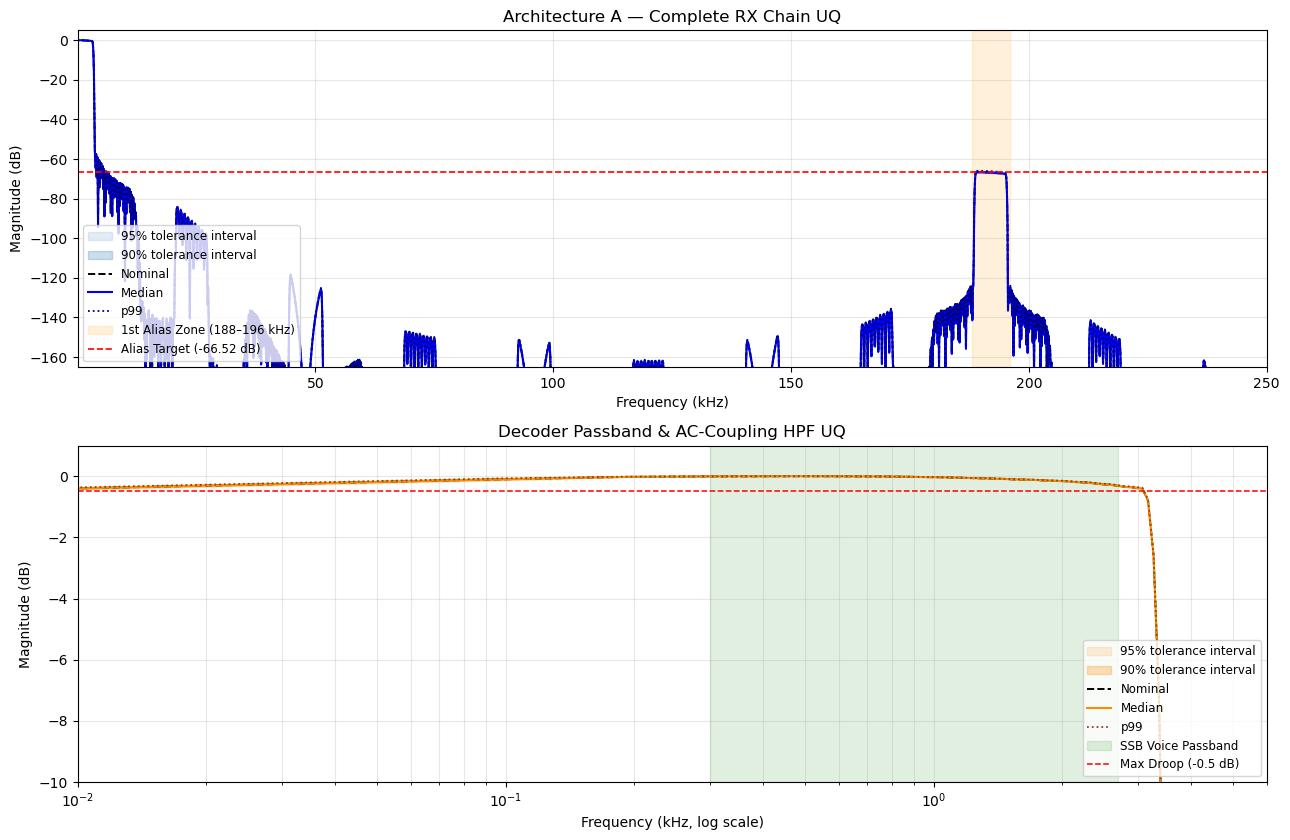


6. REV 40N FINAL SUMMARY
Sampling frequency:       192.0 kHz
Output sampling rate:     8.0 kHz
SSB bandwidth:            2.70 kHz
Alias evaluation zone:    188.0–196.0 kHz
Alias rejection target:   66.52 dB
ADC reference:            3.10 V
ADC resolution:           12 bits
ADC LSB:                  0.7568 mV
ADC acquisition budget:   2600 ns
Arch A settling:          5.41 ns
Passive RC2 feasible:     False
Arch A corner:            FAIL

END OF REV 40N ANALYSIS


In [1]:
# ============================================================
# REV 40N — COMPLETE RX AUDIO FILTER CHAIN
# Corrected engineering analysis model
#
# Architectures:
#   A: 2x OPA2320, 4 op-amps, differential gain + AAF
#   B: 3x OPA2320, 6 op-amps, unity-gain AAF + pole 3
#
# Compliance:
#   - Enumerated component tolerance corners
#   - Truncated Gaussian Monte Carlo
#   - Uniform Monte Carlo reference
#   - Per-run worst-over-alias percentile statistics
#
# IMPORTANT:
#   Frequency responses are normalized to the low-frequency
#   signal gain. Amplifier gain is handled separately in the
#   noise and clipping calculations.
# ============================================================

import itertools
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import firwin, freqz
from scipy.optimize import differential_evolution
from scipy.special import erfinv

# ============================================================
# 1. CONFIGURATION
# ============================================================

FS = 192e3
FS1 = 48e3
FS2 = 24e3
FSOUT = 8e3

R_DEC = 4
N_CIC = 4

SSB = 2.7e3
FSOUT_NYQ = FSOUT / 2

FCRIT = FS - FSOUT_NYQ
FCRIT_HI = FS + FSOUT_NYQ

BLOCKER_DBFS = -30.0
ALIAS_BELOW_NOISE_DB = 10.0
ADC_SNR_TYP = 68.0

ADC_VREF = 3.10
ADC_BITS = 12
ADC_FS_PEAK = ADC_VREF / 2
ADC_LSB = ADC_VREF / (2**ADC_BITS)
ADC_FS_DBM = 10.0

ADC_SNR_NOISE_DBFS = -ADC_SNR_TYP - 10 * np.log10(FS / SSB)

ALIAS_THRESHOLD_DBFS = ADC_SNR_NOISE_DBFS - ALIAS_BELOW_NOISE_DB

REQUIRED_REJECTION_DB = BLOCKER_DBFS - ALIAS_THRESHOLD_DBFS

TARGET = -REQUIRED_REJECTION_DB
MAX_PASS_LOSS_DB = 0.5

L_FRONTEND_DB = 0.0

# ============================================================
# 2. TAYLOE MODEL
# ============================================================

R_SOURCE_RF = 8.22
R_ON_TAYLOE = 5.0

C_TAYLOE_20M = 2.2e-9
C_TAYLOE_40M = 4.3e-9

R_SOURCE_AUDIO = 4 * (R_SOURCE_RF + R_ON_TAYLOE)

FC_TAYLOE_20M = 1 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_20M)
FC_TAYLOE_40M = 1 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_40M)

# Default analysis band
FC_TAYLOE = FC_TAYLOE_20M

# ============================================================
# 3. ARCHITECTURE A COMPONENTS
# ============================================================

C_AC = 10e-6

R1_DIFF = 1e3
RFB_DIFF = 50e3
CFB_DIFF = 220e-12

RA_SK = 10e3
CA_SK = 1.5e-9
CB_SK = 750e-12

R_KICK = 100.0
C_KICK = 1e-9

GAIN_A = RFB_DIFF / (R1_DIFF + R_SOURCE_AUDIO)
GAIN_A_DB = 20 * np.log10(GAIN_A)

# ============================================================
# 4. ARCHITECTURE B COMPONENTS
# ============================================================

# Equal-R, equal-C Butterworth Sallen-Key nominal design.
R_B_SK = 10e3
FC_B_SK = 14.7e3
C_B_SK = 1 / (2 * np.pi * R_B_SK * FC_B_SK)

R_P3 = 10e3
C_P3 = 1.08e-9

Q_SK = 1 / np.sqrt(2)

# ============================================================
# 5. ADC MODEL
# ============================================================

C_ADC = 6e-12
R_ADC_SWITCH = 0.0

T_ACQ = 2600e-9


def adc_settling(Rth, C=C_ADC, Rswitch=R_ADC_SWITCH):
    tau = (Rth + Rswitch) * C
    t_required = (ADC_BITS + 1) * np.log(2) * tau
    return tau, t_required


# ============================================================
# 6. TOLERANCE MODEL
# ============================================================

# (datasheet tolerance, assumed bin yield)

PASSIVE_MODEL = {
    "C0G": (0.05, 0.99),
    "X5R": (0.20, 0.95),
    "R1pct": (0.01, 0.99),
    "L10pct": (0.10, 0.95),
}


def tol_to_sigma(tol, yield_):
    return tol / (np.sqrt(2) * erfinv(yield_))


def draw_by_class(rng, cls, n, dist="truncnorm"):
    tol, yield_ = PASSIVE_MODEL[cls]

    if dist == "uniform":
        return rng.uniform(1 - tol, 1 + tol, n)

    if dist == "worstcase":
        return rng.choice([1 - tol, 1 + tol], size=n)

    if dist != "truncnorm":
        raise ValueError(f"Unknown distribution: {dist}")

    sigma = tol_to_sigma(tol, yield_)

    result = np.empty(n)
    filled = 0

    while filled < n:
        samples = rng.normal(0, sigma, n - filled)
        samples = samples[np.abs(samples) <= tol]

        count = len(samples)
        result[filled : filled + count] = 1 + samples
        filled += count

    return result


# ============================================================
# 7. GENERAL UTILITIES
# ============================================================


def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-15))


def wrap(f, fs):
    return (np.asarray(f) + fs / 2) % fs - fs / 2


def tayloe(f):
    return 1 / (1 + 1j * np.asarray(f) / FC_TAYLOE)


def butter(f, n, fc):
    f = np.asarray(f, float)
    return 1 / np.sqrt(1 + (f / fc) ** (2 * n))


def sallen_key(f, fc, Q=Q_SK):
    s = 1j * np.asarray(f) / fc
    return 1 / (1 + s**2 + s / Q)


# ============================================================
# 8. ANALOG TRANSFER FUNCTIONS
# ============================================================


def arch_a_old(
    f,
    c_ac=C_AC,
    r_in=R1_DIFF,
    r_fb=RFB_DIFF,
    c_fb=CFB_DIFF,
    ra=RA_SK,
    ca=CA_SK,
    cb=CB_SK,
    r_k=R_KICK,
    c_k=C_KICK,
):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    r_in_total = r_in + R_SOURCE_AUDIO

    H_hp = s * r_in_total * c_ac / (1 + s * r_in_total * c_ac)

    H_p1 = 1 / (1 + s * r_fb * c_fb)

    w0_sq = 1 / (ra**2 * ca * cb)
    a1 = 2 * ra * cb

    H_sk = w0_sq / (s**2 + s * a1 * w0_sq + w0_sq)

    H_kick = 1 / (1 + s * r_k * c_k)

    return H_hp * H_p1 * H_sk * H_kick


def arch_a(
    f,
    c_ac=C_AC,
    r_in=R1_DIFF,
    r_fb=RFB_DIFF,
    c_fb=CFB_DIFF,
    ra=RA_SK,
    ca=CA_SK,
    cb=CB_SK,
):  # r_k=R_KICK, c_k=C_KICK):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    # Differential amplifier input resistance
    r_in_total = r_in + R_SOURCE_AUDIO

    # AC coupling
    H_hp = s * r_in_total * c_ac / (1 + s * r_in_total * c_ac)

    # Differential amplifier feedback pole
    H_p1 = 1 / (1 + s * r_fb * c_fb)

    # Actual differential amplifier gain
    gain = r_fb / r_in_total

    # Component-derived Sallen-Key natural frequency
    w0 = 1 / (ra * np.sqrt(ca * cb))

    # Component-derived Sallen-Key Q
    Q = np.sqrt(ca / cb) / 2

    H_sk = w0**2 / (s**2 + s * w0 / Q + w0**2)

    # # Output isolation / ADC kickback network
    # H_kick = 1/(1+s*r_k*c_k)
    # return H_hp*H_p1*H_sk*H_kick
    return H_hp * H_p1 * H_sk


def arch_b(f, c_ac=C_AC, r_sk=R_B_SK, c_sk=C_B_SK, r_p3=R_P3, c_p3=C_P3):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    r_input = 1e6 + R_SOURCE_AUDIO

    H_hp = s * r_input * c_ac / (1 + s * r_input * c_ac)

    fc_sk = 1 / (2 * np.pi * r_sk * c_sk)

    H_sk = sallen_key(f, fc_sk)

    H_p3 = 1 / (1 + s * r_p3 * c_p3)

    return H_hp * H_sk * H_p3


# ============================================================
# 9. DIGITAL CHAIN
# ============================================================

HB = firwin(63, 12e3, fs=FS1)
POLY = firwin(161, 3.35e3, fs=FS2)


def cic(f):
    f = np.asarray(f, float)

    den = 4 * np.sin(np.pi * f / FS)
    num = np.sin(4 * np.pi * f / FS)

    ratio = np.ones_like(f)
    mask = np.abs(den) > 1e-12

    ratio[mask] = num[mask] / den[mask]

    return np.abs(ratio) ** 4


def fir_response(f, coeff, fs):
    _, h = freqz(coeff, worN=2 * np.pi * np.asarray(f) / fs)
    return np.abs(h)


def digital(f):
    f = np.asarray(f, float)

    h1 = cic(wrap(f, FS))
    h2 = fir_response(wrap(f, FS1), HB, FS1)
    h3 = fir_response(wrap(f, FS2), POLY, FS2)

    return h1 * h2 * h3


def complete(f, architecture):
    h_digital = digital(f)

    if architecture == "A":
        h_analog = arch_a(f)
    # elif architecture == "B":
    #     h_analog = arch_b(f)
    else:
        raise ValueError(architecture)

    return tayloe(f) * h_analog * h_digital


# ============================================================
# 10. PASSIVE RC2 OPTIMIZATION
# ============================================================

R_ADC_LEAK = 1e12
f_pass = np.linspace(300, SSB, 250)
f_alias = np.linspace(FCRIT, FCRIT_HI, 500)


def passive_rc(f, R1, R2, C1, C2):
    f = np.atleast_1d(np.asarray(f, float))
    s = 2j * np.pi * f

    G1 = 1 / (R_SOURCE_AUDIO + R1)
    G2 = 1 / R2
    GL = 1 / R_ADC_LEAK

    b = np.array([G1, 0], dtype=complex)

    result = np.empty(len(f), dtype=complex)

    for i, si in enumerate(s):
        A = np.array(
            [[G1 + G2 + si * C1, -G2], [-G2, G2 + GL + si * C2]], dtype=complex
        )

        result[i] = np.linalg.solve(A, b)[1]

    return result


def passive_objective(x):
    R1, R2, C1, C2 = 10 ** np.asarray(x)

    hp = db(passive_rc(f_pass, R1, R2, C1, C2))
    ha = db(passive_rc(f_alias, R1, R2, C1, C2))

    _, t_req = adc_settling(R_SOURCE_AUDIO + R1 + R2)

    pass_violation = max(0, -np.min(hp) - MAX_PASS_LOSS_DB)

    alias_violation = max(0, np.max(ha) - TARGET)

    settle_violation = max(0, (t_req - T_ACQ) / T_ACQ)

    return alias_violation**2 + 1000 * pass_violation**2 + 1000 * settle_violation**2


result = differential_evolution(
    passive_objective,
    [(0, 5), (0, 5), (-12, -5), (-12, -5)],
    seed=42,
    popsize=20,
    maxiter=400,
    tol=1e-7,
    polish=True,
)

R1_OPT, R2_OPT, C1_OPT, C2_OPT = 10**result.x

HP_OPT = db(passive_rc(f_pass, R1_OPT, R2_OPT, C1_OPT, C2_OPT))

HA_OPT = db(passive_rc(f_alias, R1_OPT, R2_OPT, C1_OPT, C2_OPT))

_, T_REQ_OPT = adc_settling(R_SOURCE_AUDIO + R1_OPT + R2_OPT)

PASSIVE_FEASIBLE = (
    np.min(HP_OPT) >= -MAX_PASS_LOSS_DB
    and np.max(HA_OPT) <= TARGET
    and T_ACQ >= T_REQ_OPT
)


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ============================================================
# 11. CORNER ANALYSIS
# ============================================================

section("0. EXHAUSTIVE COMPONENT CORNER ANALYSIS")

COMPONENTS_A = [
    ("c_ac", C_AC, "X5R"),
    ("r_in", R1_DIFF, "R1pct"),
    ("r_fb", RFB_DIFF, "R1pct"),
    ("c_fb", CFB_DIFF, "C0G"),
    ("ra", RA_SK, "R1pct"),
    ("ca", CA_SK, "C0G"),
    ("cb", CB_SK, "C0G"),
    # ("r_k", R_KICK, "R1pct"),
    # ("c_k", C_KICK, "C0G"),
]

COMPONENTS_B = [
    ("c_ac", C_AC, "X5R"),
    ("r_sk", R_B_SK, "R1pct"),
    ("c_sk", C_B_SK, "C0G"),
    ("r_p3", R_P3, "R1pct"),
    ("c_p3", C_P3, "C0G"),
]


def corner_worst(architecture, f_grid):

    if architecture != "A":
        raise ValueError(f"Unsupported architecture: {architecture}")

    components = COMPONENTS_A if architecture == "A" else COMPONENTS_B

    mask = (f_grid >= FCRIT) & (f_grid <= FCRIT_HI)

    h_dig = digital(f_grid)
    h_tay = tayloe(f_grid)

    worst = -np.inf
    worst_signs = None

    for signs in itertools.product((-1, 1), repeat=len(components)):

        kwargs = {
            name: nominal * (1 + sign * PASSIVE_MODEL[cls][0])
            for (name, nominal, cls), sign in zip(components, signs)
        }

        if architecture == "A":
            h = arch_a(f_grid, **kwargs)
        # elif architecture == "B":
        #    h = arch_b(f_grid, **kwargs)
        else:
            raise Exception(f"Unsupported architecture: {architecture}")

        response = db(h_tay * h * h_dig)
        value = float(np.max(response[mask]))

        if value > worst:
            worst = value
            worst_signs = signs

    return worst, worst_signs, components


# Frequency grid covering the complete alias evaluation band.
f_corner = np.linspace(FCRIT, FCRIT_HI, 2001)

corner_results = {}

arch_map = [
    ("A", "Architecture A — 2x OPA2320"),
    # ("B", "Architecture B — 3x OPA2320"),
]

for arch_key, arch_name in arch_map:

    worst_db, worst_signs, components = corner_worst(arch_key, f_corner)

    margin = TARGET - worst_db
    passed = worst_db <= TARGET

    corner_results[arch_key] = {
        "worst_db": worst_db,
        "worst_signs": worst_signs,
        "components": components,
        "margin_db": margin,
        "passed": passed,
    }

    print(f"\n{arch_name}")
    print(f"  Number of corners: {2**len(components)}")
    print(f"  Worst alias response: {worst_db:+.2f} dB")
    print(f"  Required maximum: {TARGET:+.2f} dB")
    print(f"  Compliance margin: {margin:+.2f} dB")
    print(f"  Verdict: {'PASS' if passed else 'FAIL'}")

    print("  Worst-case component values:")

    for (name, nominal, cls), sign in zip(components, worst_signs):
        tolerance = PASSIVE_MODEL[cls][0]
        value = nominal * (1 + sign * tolerance)

        print(f"    {name:<8} = {value:.6g}")

# ============================================================
# 12. MONTE CARLO
# ============================================================


def simulate_mc(architecture, f_grid, n_runs=5000, dist="truncnorm", seed=42):

    rng = np.random.default_rng(seed)

    h_dig = digital(f_grid)
    h_tay = tayloe(f_grid)

    mask = (f_grid >= FCRIT) & (f_grid <= FCRIT_HI)

    if architecture != "A":
        raise ValueError(f"Unsupported architecture: {architecture}")

    components = COMPONENTS_A if architecture == "A" else COMPONENTS_B

    factors = {}

    for name, nominal, cls in components:
        factors[name] = draw_by_class(rng, cls, n_runs, dist)

    mc = np.empty((n_runs, len(f_grid)))

    if architecture == "A":
        nominal = db(h_tay * arch_a(f_grid) * h_dig)
    # elif architecture == "B":
    #    nominal = db(h_tay*arch_b(f_grid)*h_dig)
    else:
        raise Exception(f"Unsupported architecture: {architecture}")

    for k in range(n_runs):

        kwargs = {
            name: nominal_value * factors[name][k]
            for name, nominal_value, cls in components
        }

        if architecture == "A":
            h = arch_a(f_grid, **kwargs)
        # elif architecture == "B":
        #    h = arch_b(f_grid, **kwargs)
        else:
            raise Exception(f"Unsupported architecture: {architecture}")

        mc[k] = db(h_tay * h * h_dig)

    # Critical: maximum is taken within each run first.
    worst_per_run = np.max(mc[:, mask], axis=1)

    return {
        "mc": mc,
        "nominal": nominal,
        "worst_per_run": worst_per_run,
        "alias_mask": mask,
    }


# ============================================================
# 13. MONTE CARLO PLOTS
# ============================================================



def plot_audio_uq(architecture, f_grid, n_runs=5000):

    r = simulate_mc(architecture, f_grid, n_runs=n_runs, dist="truncnorm")

    mc = r["mc"]
    nominal = r["nominal"]
    worst = r["worst_per_run"]

    print(f"\nArchitecture {architecture} — Alias rejection statistics")
    print("-" * 68)
    print(f"{'Level':<10} {'Quantile':>11} {'Response':>13} {'Margin':>12} {'Verdict':>9}")
    print("-" * 68)

    levels = [
        ("Median", 50),
        ("1 sigma", 84.1345),
        ("2 sigma", 97.7250),
        ("3 sigma", 99.8650),
        ("4 sigma", 99.99683),
        ("5 sigma", 99.9999713),
        ("6 sigma", 99.9999999),
        ("Maximum", 100),
    ]

    for label, q in levels:
        value = np.percentile(worst, q)
        margin = TARGET - value
        verdict = "PASS" if margin >= 0 else "FAIL"

        print(
            f"{label:<10} {q:>10.5f}% "
            f"{value:>+12.2f} dB "
            f"{margin:>+10.2f} dB "
            f"{verdict:>9}"
        )

    print("-" * 68)

    p2_5, p5, p50, p95, p97_5, p99 = [
        np.percentile(mc, p, axis=0)
        for p in (2.5, 5, 50, 95, 97.5, 99)
    ]

    f_khz = f_grid / 1e3

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5))

    # --------------------------------------------------------
    # COMPLETE RX CHAIN
    # --------------------------------------------------------

    ax1.fill_between(
        f_khz, p2_5, p97_5,
        alpha=0.14, color="steelblue",
        label="95% tolerance interval"
    )

    ax1.fill_between(
        f_khz, p5, p95,
        alpha=0.28, color="steelblue",
        label="90% tolerance interval"
    )

    ax1.plot(f_khz, nominal, "k--", lw=1.4, label="Nominal")
    ax1.plot(f_khz, p50, color="blue", lw=1.5, label="Median")
    ax1.plot(f_khz, p99, ":", color="navy", lw=1.3, label="p99")

    ax1.axvspan(
        FCRIT / 1e3, FCRIT_HI / 1e3,
        color="orange", alpha=0.15,
        label="1st Alias Zone (188–196 kHz)"
    )

    ax1.axhline(
        TARGET, color="red", ls="--", lw=1.2,
        label=f"Alias Target ({TARGET:.2f} dB)"
    )

    ax1.set_xlim(0.01, 250)
    ax1.set_ylim(-165, 5)
    ax1.set_title(
        f"Architecture {architecture} — Complete RX Chain UQ"
    )
    ax1.set_xlabel("Frequency (kHz)")
    ax1.set_ylabel("Magnitude (dB)")
    ax1.grid(alpha=0.3)
    ax1.legend(loc="lower left", fontsize=8.5)

    # --------------------------------------------------------
    # DECODER PASSBAND
    # --------------------------------------------------------

    ax2.fill_between(
        f_khz, p2_5, p97_5,
        alpha=0.14, color="darkorange",
        label="95% tolerance interval"
    )

    ax2.fill_between(
        f_khz, p5, p95,
        alpha=0.28, color="darkorange",
        label="90% tolerance interval"
    )

    ax2.plot(f_khz, nominal, "k--", lw=1.4, label="Nominal")
    ax2.plot(f_khz, p50, color="darkorange", lw=1.5, label="Median")
    ax2.plot(f_khz, p99, ":", color="saddlebrown", lw=1.3, label="p99")

    ax2.axvspan(
        0.3, SSB / 1e3,
        color="green", alpha=0.12,
        label="SSB Voice Passband"
    )

    ax2.axhline(
        -MAX_PASS_LOSS_DB, color="red", ls="--", lw=1.1,
        label=f"Max Droop (-{MAX_PASS_LOSS_DB} dB)"
    )

    ax2.set_xscale("log")
    ax2.set_xlim(0.01, 6.0)
    ax2.set_ylim(-10, 1)
    ax2.set_title("Decoder Passband & AC-Coupling HPF UQ")
    ax2.set_xlabel("Frequency (kHz, log scale)")
    ax2.set_ylabel("Magnitude (dB)")
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(loc="lower right", fontsize=8.5)

    plt.tight_layout()
    plt.show()

    return r
    
# ============================================================
# 14. SECTION 1 — TAYLOE
# ============================================================

section("1. TAYLOE BASEBAND")

print(f"RF source resistance: {R_SOURCE_RF:.2f} ohm")
print(f"Tayloe switch Ron: {R_ON_TAYLOE:.2f} ohm")
print(f"Four-phase audio source: {R_SOURCE_AUDIO:.2f} ohm")
print(f"20m cutoff: {FC_TAYLOE_20M/1e6:.3f} MHz")
print(f"40m cutoff: {FC_TAYLOE_40M/1e6:.3f} MHz")
print(f"Front-end insertion loss: {L_FRONTEND_DB:.2f} dB")


# ============================================================
# 15. SECTION 2 — PASSIVE RC2
# ============================================================

section("2. PASSIVE RC2 OPTIMIZATION")

print(f"R1: {R1_OPT:.2f} ohm")
print(f"R2: {R2_OPT:.2f} ohm")
print(f"C1: {C1_OPT*1e9:.3f} nF")
print(f"C2: {C2_OPT*1e9:.3f} nF")

print(f"Passband minimum: {np.min(HP_OPT):.3f} dB")
print(f"Alias maximum: {np.max(HA_OPT):.3f} dB")
print(f"Required settling: {T_REQ_OPT*1e9:.2f} ns")
print(f"Available acquisition: {T_ACQ*1e9:.2f} ns")
print(f"Feasible: {PASSIVE_FEASIBLE}")


# ============================================================
# 16. SECTION 3 — ADC SETTLING
# ============================================================

section("3. ADC SETTLING")

RTH_A = R_KICK
RTH_B = R_P3

for name, rth in [
    ("Arch A", RTH_A),
    # ("Arch B", RTH_B),
    ("Passive RC2", R_SOURCE_AUDIO + R1_OPT + R2_OPT),
]:

    tau, required = adc_settling(rth)

    print(
        f"{name:<14} Rth={rth:9.2f} ohm | "
        f"tau={tau*1e9:8.3f} ns | "
        f"required={required*1e9:8.3f} ns | "
        f"{'PASS' if T_ACQ >= required else 'FAIL'}"
    )


# Idealized charge sharing if C_P3 is directly connected
# to the ADC sampling capacitor during acquisition.
charge_error = C_ADC / (C_P3 + C_ADC)
charge_error_lsb = charge_error * (2**ADC_BITS)

print("\nArch B idealized charge-sharing estimate:")
print(f"Error fraction: {100*charge_error:.4f}%")
print(f"Error in ADC LSB: {charge_error_lsb:.2f} LSB")


# ============================================================
# SECTION 8 — FINAL COMPLIANCE VERDICT
# ============================================================

section("4. FINAL DESIGN COMPLIANCE VERDICT")

corner_a_failed = not corner_results["A"]["passed"]
corner_b_failed = False  # not corner_results["B"]["passed"]

print(f"Compliance target: {TARGET:+.2f} dB")
print()

for arch_key, arch_name in arch_map:

    result = corner_results[arch_key]

    print(f"{arch_name}:")
    print(f"  Worst component corner: {result['worst_db']:+.2f} dB")
    print(f"  Required maximum:       {TARGET:+.2f} dB")
    print(f"  Compliance margin:      {result['margin_db']:+.2f} dB")
    print(f"  Verdict:                {'PASS' if result['passed'] else 'FAIL'}")
    print()

if corner_a_failed or corner_b_failed:

    section("VERDICT — CORNER FAIL")

    if corner_a_failed:
        print("Arch A: FAIL")

    if corner_b_failed:
        print("Arch B: FAIL")

    print()
    print("Do not claim component-tolerance compliance.")

else:

    section("VERDICT — CORNER PASS")

    print("Arch A: PASS")
    print("Arch B: PASS")
    print()
    print("Both architectures pass the enumerated")
    print("component-tolerance corner analysis.")

# ============================================================
# 5. ARCHITECTURE A MONTE CARLO ANALYSIS
# ============================================================

section("5. ARCHITECTURE A MONTE CARLO ANALYSIS")

mc_results_A = plot_audio_uq(
    architecture="A", f_grid=np.linspace(0, FS * 1.5, 3000), n_runs=5000
)

# ============================================================
# SECTION 10 — SUMMARY
# ============================================================

section("6. REV 40N FINAL SUMMARY")

print(f"Sampling frequency:       {FS/1e3:.1f} kHz")
print(f"Output sampling rate:     {FSOUT/1e3:.1f} kHz")
print(f"SSB bandwidth:            {SSB/1e3:.2f} kHz")
print(f"Alias evaluation zone:    {FCRIT/1e3:.1f}–{FCRIT_HI/1e3:.1f} kHz")
print(f"Alias rejection target:   {-TARGET:.2f} dB")
print(f"ADC reference:            {ADC_VREF:.2f} V")
print(f"ADC resolution:           {ADC_BITS} bits")
print(f"ADC LSB:                  {ADC_LSB*1e3:.4f} mV")
print(f"ADC acquisition budget:   {T_ACQ*1e9:.0f} ns")
print(f"Arch A settling:          {adc_settling(RTH_A)[1]*1e9:.2f} ns")
# print(f"Arch B settling:          {adc_settling(RTH_B)[1]*1e9:.2f} ns")
print(f"Passive RC2 feasible:     {PASSIVE_FEASIBLE}")
print(f"Arch A corner:            {'FAIL' if corner_a_failed else 'PASS'}")
# print(f"Arch B corner:            {'FAIL' if corner_b_failed else 'PASS'}")
print()
print("END OF REV 40N ANALYSIS")
